# Taller: Random Forest


### Aprendizaje Supervisado — Bootstrap, variables aleatorias y votación con `RandomForestClassifier`


**Pontificia Universidad Católica del Ecuador · Carrera de Ingeniería de Sistemas de Información**

**Asignatura:** Inteligencia Artificial · Sexto Semestre

**Nombre del estudiante:** Paúl Rosero

**Fecha:** 15-10-2026

> **Cómo usar este material:** este taller es una **guía de referencia en HTML**, no un notebook interactivo.
> Reproduce cada celda de código en tu propio Google Colab o Jupyter Notebook, en el mismo orden en que
> aparece: cada bloque usa los objetos creados en el anterior. Necesitas los archivos
> `jugadores_liga_pro.csv` (Partes A y C) y `rendimiento_seleccion.csv` (Parte B).


## Objetivos del taller


Al finalizar este taller el estudiante será capaz de:

1. Entrenar un `RandomForestClassifier` dentro de un `Pipeline` y compararlo con un árbol de decisión.
2. Explicar con datos reales cómo vota el bosque y qué devuelve `predict_proba()`.
3. Interpretar el **OOB score** (Out-of-Bag) y la **importancia de variables** del bosque.
4. Reentrenar el modelo final con el 100% de los datos, exportarlo con `joblib` y usarlo con datos nuevos.


## Datasets (sintéticos, sin valores nulos)


**`jugadores_liga_pro.csv`** — 900 jugadores de la LigaPro de Ecuador. Partes A y C.

| Variable | Tipo | Descripción |
| --- | --- | --- |
| `jugador_id` | Identificador | No se usa para predecir |
| `equipo` | Texto | Club (10 equipos) |
| `posicion` | Texto | Portero, Defensa, Mediocampista o Delantero |
| `edad` | Numérica | Años (18 a 37) |
| `partidos_jugados` | Numérica | Partidos en la temporada (2 a 34) |
| `minutos_jugados` | Numérica | Minutos totales en la temporada |
| `goles_por_partido` | Numérica | Promedio de goles por partido |
| `asistencias` | Numérica | Pases de gol en la temporada |
| `pases_completados_pct` | Numérica | % de pases completados |
| `tarjetas_amarillas` | Numérica | Tarjetas amarillas en la temporada |
| `tarjetas_rojas` | Numérica | Tarjetas rojas en la temporada |
| `convocado` | Objetivo (y) | 1 = convocado a la Selección · 0 = no |

**`rendimiento_seleccion.csv`** — 600 registros de jugadores convocados a partidos de la Selección. Parte B.

| Variable | Tipo | Descripción |
| --- | --- | --- |
| `convocatoria_id` | Identificador | No se usa para predecir |
| `posicion` | Texto | Posición del jugador |
| `edad` | Numérica | Años |
| `partidos_seleccion` | Numérica | Partidos jugados con la Selección hasta esa fecha |
| `goles_seleccion` | Numérica | Goles con la Selección hasta esa fecha |
| `promedio_calificacion` | Numérica | Calificación promedio en sus últimos partidos (escala 1 a 10) |
| `ranking_rival_fifa` | Numérica | Puesto del rival en el ranking FIFA |
| `local_visitante` | Texto | Local o Visitante |
| `competencia` | Texto | Eliminatoria, Amistoso, Copa America o Mundial |
| `lesion_reciente` | Numérica (0/1) | 1 = tuvo una lesión reciente |
| `titular` | Objetivo (y) | 1 = fue titular en ese partido · 0 = suplente |


## Estructura del taller


| Bloque | Tipo | Contenido |
| --- | --- | --- |
| A1 | Guiado | Carga y exploración |
| A2 | Guiado | X, y y división train/test |
| A3 | Guiado | Codificar el texto con `ColumnTransformer` |
| A4 | Guiado | Baseline: árbol de decisión sin límite |
| A5 | Guiado | `RandomForestClassifier` en un `Pipeline` |
| A6 | Guiado | Comparación árbol vs. bosque |
| A7 | Guiado | La votación del bosque, árbol por árbol |
| A8 | Guiado | OOB score vs. accuracy en prueba |
| A9 | Guiado | Importancia de variables |
| A10 | Guiado | Efecto del número de árboles (`n_estimators`) |
| B1 | Autónomo | Titularidad: datos, división y codificación |
| B2 | Autónomo | Titularidad: árbol vs. bosque y OOB |
| B3 | Autónomo | Titularidad: importancia de variables e interpretación |
| C | Guiado | Entrenamiento final (100%), exportación y uso con datos nuevos |


## Rúbrica de evaluación (10 puntos)


| Componente | Qué se evalúa | Puntos |
| --- | --- | --- |
| Bloques A1–A10 y C (guiados) | Reproducidos completos y sin errores en tu notebook | 1.5 |
| Bloque B1 (autónomo) | Código correcto: carga, `X`/`y`, división estratificada y `ColumnTransformer` | 2.0 |
| Bloque B2 (autónomo) | Código correcto (1.5) + tabla y respuestas de análisis (1.5) | 3.0 |
| Bloque B3 (autónomo) | Código correcto (1.5) + respuestas de análisis (2.0) | 3.5 |
| **Total** | | **10.0** |


# Parte A — Laboratorio Guiado: Convocatoria a la Selección


## Bloque A1 · Carga y exploración


**Librerías que usamos:** `pandas` (datos) y `matplotlib.pyplot` (gráficos).


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('jugadores_liga_pro.csv')
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
print("Valores nulos:", df.isnull().sum().sum())
df.head()


Filas: 900 | Columnas: 12
Valores nulos: 0


,jugador_id,equipo,posicion,edad,partidos_jugados,minutos_jugados,goles_por_partido,asistencias,pases_completados_pct,tarjetas_amarillas,tarjetas_rojas,convocado
0,JUG0001,Macará,Mediocampista,27,22,954,0.17,4,81.8,5,0,0
1,JUG0002,Liga de Quito,Delantero,20,17,1201,0.26,2,72.4,4,1,0
2,JUG0003,Liga de Quito,Mediocampista,32,21,1399,0.12,3,96.0,3,1,0
3,JUG0004,Universidad Católica,Defensa,34,21,1433,0.06,0,89.6,6,0,0
4,JUG0005,El Nacional,Defensa,26,6,269,0.05,0,85.1,2,0,0


convocado
0    675
1    225
Name: count, dtype: int64


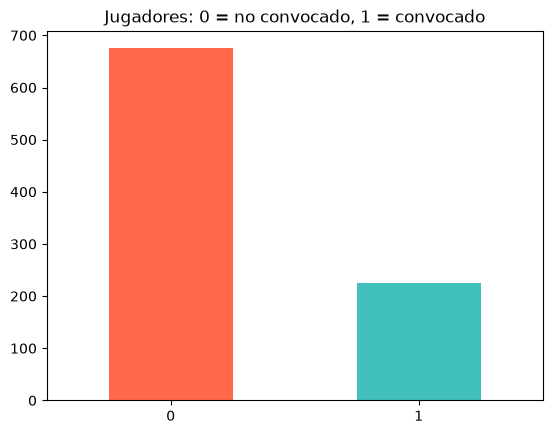

In [2]:
conteo = df['convocado'].value_counts()
print(conteo)

ax = conteo.plot(kind='bar', color=['#FF6849', '#41BFBC'])
ax.set_title('Jugadores: 0 = no convocado, 1 = convocado')
ax.set_xlabel('')
plt.xticks(rotation=0)
plt.show()


**Observación:** 675 no convocados (75%) y 225 convocados (25%): las clases están **desbalanceadas** (3 a 1).
Por eso, además de **Accuracy**, miraremos **Recall** y **F1** de la clase Convocado (rango 0 a 1 → 1 = deseado).


## Bloque A2 · X, y y división train/test


**Librería:** `train_test_split`.

* `X` = las 10 variables predictoras (sin `jugador_id`, que solo identifica al jugador) · `y` = `convocado`.
* `stratify=y` mantiene el 25% de convocados tanto en entrenamiento como en prueba.
* `X_test` se reserva para medir el modelo con jugadores que **no vio** al entrenar.


In [3]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['jugador_id', 'convocado'])
y = df['convocado']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Entrenamiento: {X_train.shape[0]} filas | % convocados: {y_train.mean() * 100:.1f}%")
print(f"Prueba:        {X_test.shape[0]} filas | % convocados: {y_test.mean() * 100:.1f}%")


Entrenamiento: 720 filas | % convocados: 25.0%
Prueba:        180 filas | % convocados: 25.0%


## Bloque A3 · Codificar el texto con `ColumnTransformer`


**Librerías:** `ColumnTransformer`, `OneHotEncoder` y `Pipeline` (las vimos en Regresión Logística).

* `equipo` y `posicion` son **texto**; scikit-learn solo acepta números. `OneHotEncoder` crea una columna 0/1 por cada categoría (`equipo_Emelec`, `posicion_Defensa`, …).
* `ColumnTransformer` aplica el `OneHotEncoder` solo a esas dos columnas y deja pasar las numéricas con `remainder='passthrough'`.


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

cols_texto = ['equipo', 'posicion']

preproc = ColumnTransformer(
    [('cat', OneHotEncoder(handle_unknown='ignore'), cols_texto)],
    remainder='passthrough')


## Bloque A4 · Baseline: árbol de decisión sin límite


**Librería:** `DecisionTreeClassifier` (clase anterior). Lo usamos **sin límite de profundidad** para ver el problema que Random Forest resuelve.

* El `Pipeline` junta la codificación del texto y el árbol en un solo objeto.
* Los árboles crecen hasta que cada hoja tiene datos de una sola clase.


In [5]:
from sklearn.tree import DecisionTreeClassifier

arbol = Pipeline([('preproc', preproc),
                  ('modelo', DecisionTreeClassifier(random_state=42))])
arbol.fit(X_train, y_train)

print("Hojas del árbol:", arbol.named_steps['modelo'].get_n_leaves())
print(f"Accuracy entrenamiento: {arbol.score(X_train, y_train):.3f}")
print(f"Accuracy prueba:        {arbol.score(X_test, y_test):.3f}")


Hojas del árbol: 91
Accuracy entrenamiento: 1.000
Accuracy prueba:        0.778


**Observación:** 1.000 en entrenamiento y 0.778 en prueba. El árbol memorizó el ruido: sobreajuste clásico.


## Bloque A5 · `RandomForestClassifier` en un `Pipeline`


**Librería:** `RandomForestClassifier`.

* `n_estimators=100`: entrenamos 100 árboles distintos (el valor por defecto de scikit-learn).
* `oob_score=True`: calcula el desempeño con las filas no usadas en el bootstrap de cada árbol.
* `random_state=42`: hace repetible el sorteo de filas (bootstrap) y de variables (√p en cada división).


In [6]:
from sklearn.ensemble import RandomForestClassifier

bosque = Pipeline([('preproc', preproc),
                   ('modelo', RandomForestClassifier(n_estimators=100,
                                                     oob_score=True,
                                                     random_state=42))])
bosque.fit(X_train, y_train)

print(f"Accuracy entrenamiento: {bosque.score(X_train, y_train):.3f}")
print(f"Accuracy prueba:        {bosque.score(X_test, y_test):.3f}")


Accuracy entrenamiento: 1.000
Accuracy prueba:        0.878


**Observación:** en entrenamiento sigue siendo 1.000 (cada árbol individual sigue creciendo sin límite), pero en prueba sube de 0.778 a 0.878 (+10 puntos porcentuales). El promedio de muchos árboles cancela los errores individuales.


## Bloque A6 · Comparación árbol vs. bosque


**Librerías:** `classification_report` y `ConfusionMatrixDisplay`.


In [7]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

y_pred_arbol = arbol.predict(X_test)
y_pred_bosque = bosque.predict(X_test)

print("=== ÁRBOL SIN LÍMITE ===")
print(classification_report(y_test, y_pred_arbol, target_names=['No convocado', 'Convocado']))

print("=== RANDOM FOREST (100 árboles) ===")
print(classification_report(y_test, y_pred_bosque, target_names=['No convocado', 'Convocado']))


=== ÁRBOL SIN LÍMITE ===
              precision    recall  f1-score   support
No convocado       0.87      0.83      0.85       135
   Convocado       0.55      0.62      0.58        45
    accuracy                           0.78       180
   macro avg       0.71      0.73      0.72       180
weighted avg       0.79      0.78      0.78       180
=== RANDOM FOREST (100 árboles) ===
              precision    recall  f1-score   support
No convocado       0.87      0.98      0.92       135
   Convocado       0.90      0.58      0.70        45
    accuracy                           0.88       180
   macro avg       0.89      0.78      0.81       180
weighted avg       0.88      0.88      0.87       180


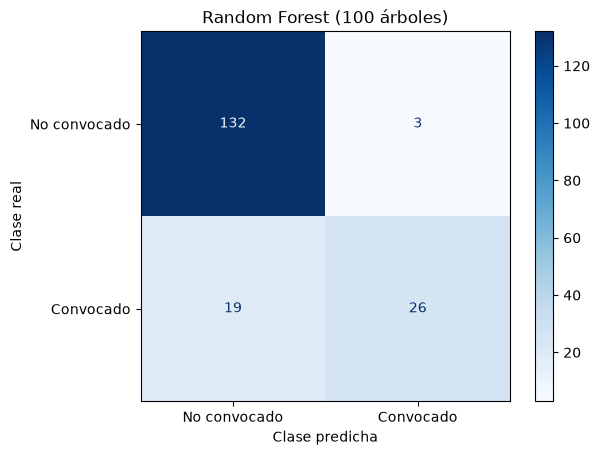

In [8]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_bosque, display_labels=['No convocado', 'Convocado'], cmap='Blues')
plt.title('Random Forest (100 árboles)')
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.show()


| Modelo | Accuracy | Precision (Conv.) | Recall (Conv.) | F1 (Conv.) |
| --- | --- | --- | --- | --- |
| Árbol sin límite | 0.778 | 0.549 | 0.622 | 0.583 |
| Random Forest | **0.878** | **0.897** | 0.578 | **0.703** |

* El bosque mejora el Accuracy en 10 puntos y el F1 de Convocado de 0.583 a 0.703.
* Su Precision es muy alta (cuando dice "convocado" casi siempre acierta), aunque detecta 26 de los 45 convocados (Recall 0.578): es un modelo **prudente**.


## Bloque A7 · La votación del bosque, árbol por árbol


`named_steps` recupera cada paso del `Pipeline` ya entrenado: `rf` es el bosque y `pre` el codificador. `rf.estimators_` es la lista de los 100 árboles. Preguntamos a cada árbol por el jugador **JUG0080** (índice 79 del DataFrame, que quedó en el conjunto de prueba).

Cada árbol recibe el jugador **ya codificado** (`pre.transform`), porque los árboles internos no conocen el texto.


In [9]:
rf = bosque.named_steps['modelo']
pre = bosque.named_steps['preproc']

jugador = X_test.loc[[79]]              # JUG0080 (doble corchete = DataFrame de 1 fila)
jugador_cod = pre.transform(jugador)    # mismas 22 columnas que vio cada árbol

votos = [arbol_i.predict(jugador_cod)[0] for arbol_i in rf.estimators_]

print("Árboles en el bosque:", len(rf.estimators_))
print("Votos 'Convocado':   ", int(sum(votos)))
print("Votos 'No':          ", len(votos) - int(sum(votos)))
print("Predicción del bosque:", bosque.predict(jugador))
print("predict_proba:        ", bosque.predict_proba(jugador))
jugador


Árboles en el bosque: 100
Votos 'Convocado':    68
Votos 'No':           32
Predicción del bosque: [1]
predict_proba:         [[0.32 0.68]]


,equipo,posicion,edad,partidos_jugados,minutos_jugados,goles_por_partido,asistencias,pases_completados_pct,tarjetas_amarillas,tarjetas_rojas
79,Universidad Católica,Defensa,25,10,484,0.05,1,89.9,0,0


**Lectura:** 68 árboles votan *Convocado* y 32 *No* → el bosque predice **Convocado** (y es correcto).

`predict_proba()` devuelve `[0.32, 0.68]`. Ojo: scikit-learn **no cuenta votos**, sino que **promedia las probabilidades** de los 100 árboles. Como los árboles crecen sin límite, cada hoja es pura (probabilidad 0 o 1) y el promedio coincide con la proporción de votos.


## Bloque A8 · OOB score vs. accuracy en prueba


Cada árbol se entrenó con 720 filas sorteadas con reemplazo, que contienen ≈ 63% de jugadores distintos; el ≈ 37% restante (**Out-of-Bag**) no lo vio.
El **OOB score** evalúa a cada jugador solo con los árboles que no lo vieron. Rango 0 a 1 → 1 = deseado.


In [10]:
print(f"OOB score (sin tocar X_test): {rf.oob_score_:.3f}")
print(f"Accuracy en prueba:           {bosque.score(X_test, y_test):.3f}")


OOB score (sin tocar X_test): 0.826
Accuracy en prueba:           0.878


**Lectura:** OOB ≈ 0.83 y prueba ≈ 0.88. Ambos estiman cómo le irá al modelo con jugadores nuevos.
La diferencia se debe al azar: la prueba usa solo 180 jugadores, mientras que el OOB se calcula con los 720 de entrenamiento. El OOB es útil cuando no se quiere (o no se puede) apartar un conjunto de prueba.


## Bloque A9 · Importancia de variables


`feature_importances_`: cuánto redujo cada variable la impureza (Gini), **promediado en los 100 árboles**.
Rango 0 a 1; la suma de todas es 1. `get_feature_names_out()` da los nombres de las 22 columnas.


remainder__pases_completados_pct    0.227
remainder__goles_por_partido        0.174
remainder__minutos_jugados          0.107
remainder__edad                     0.094
remainder__partidos_jugados         0.081
remainder__asistencias              0.074
remainder__tarjetas_amarillas       0.061
remainder__tarjetas_rojas           0.022
cat__posicion_Portero               0.016
cat__posicion_Defensa               0.015
dtype: float64


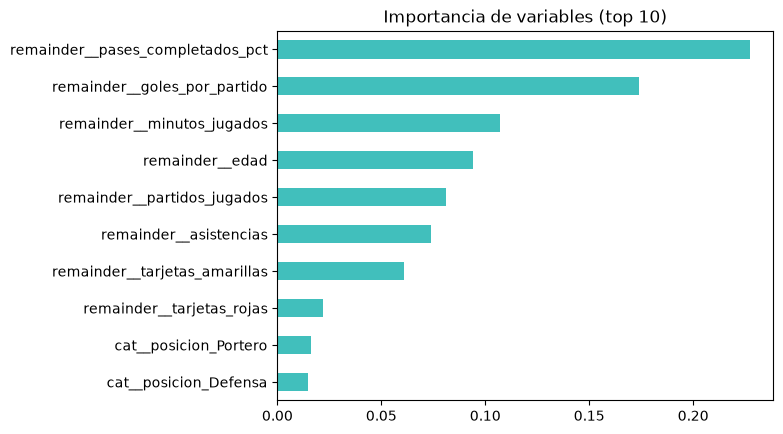

In [11]:
importancia = pd.Series(rf.feature_importances_, index=pre.get_feature_names_out())
importancia = importancia.sort_values(ascending=False)
print(importancia.head(10).round(3))

ax = importancia.head(10).sort_values().plot(kind='barh', color='#41BFBC')
ax.set_title('Importancia de variables (top 10)')
plt.show()


**Lectura:**

* `pases_completados_pct` (0.227) y `goles_por_partido` (0.174) son las más usadas por el bosque, seguidas de `minutos_jugados`.
* Cada columna One-Hot (ej. `posicion_Defensa`) recibe una importancia pequeña porque la variable original se reparte en varias columnas.
* La importancia dice **qué usó el modelo**, no causa y efecto.


## Bloque A10 · Efecto del número de árboles (`n_estimators`)


Entrenamos bosques con 1, 5, 10, 25, 50, 100 y 300 árboles y medimos el accuracy en prueba.


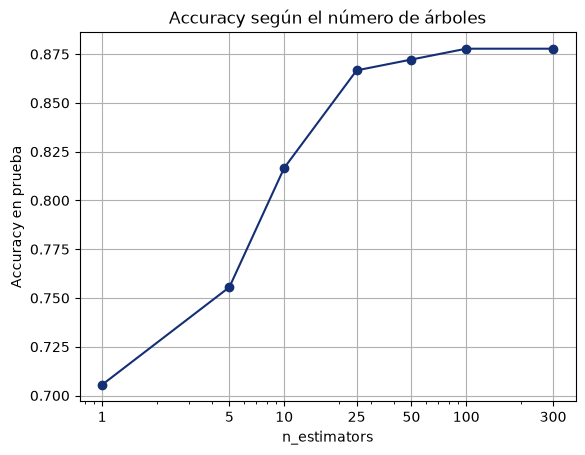

,Accuracy prueba
n_estimators,
1,0.706
5,0.756
10,0.817
25,0.867
50,0.872
100,0.878
300,0.878


In [12]:
resultados = []
for n in [1, 5, 10, 25, 50, 100, 300]:
    modelo_n = Pipeline([('preproc', preproc),
                         ('modelo', RandomForestClassifier(n_estimators=n, random_state=42))])
    modelo_n.fit(X_train, y_train)
    resultados.append({'n_estimators': n, 'Accuracy prueba': modelo_n.score(X_test, y_test)})

curva = pd.DataFrame(resultados).set_index('n_estimators')
ax = curva.plot(marker='o', logx=True, grid=True, color='#152F75', legend=False)
ax.set_xticks(curva.index, curva.index)   # etiquetas 1, 5, 10… en vez de 10⁰, 10¹
ax.set_ylabel('Accuracy en prueba')
ax.set_title('Accuracy según el número de árboles')
plt.show()
curva.round(3)


**Lectura:** con 1 árbol el accuracy es ≈ 0.71; sube rápido hasta ≈ 0.87 con 25 árboles y después **se estabiliza**.
Agregar más árboles no produce sobreajuste: solo aumenta el tiempo de entrenamiento. Por eso el valor por defecto (100) suele ser suficiente.


# Parte B — Práctica Autónoma: ¿Será Titular?


**Contexto:** el cuerpo técnico de la Selección quiere anticipar qué convocados serán **titulares** en cada partido usando `rendimiento_seleccion.csv`. Objetivo: predecir `titular` (1 = titular).

En **tu propio notebook**, escribe el código que reemplace cada `# TODO` que ves en esta guía y responde las preguntas en una celda de texto. Sigue la misma secuencia de la Parte A, con nombres terminados en `_b`.


## Bloque B1 · Datos, división y codificación


Este dataset tiene **3 columnas de texto**: `posicion`, `local_visitante` y `competencia`.


In [13]:
# TODO 1: carga 'rendimiento_seleccion.csv' en df_b y muestra cuántos casos hay de cada clase de 'titular'
df_b = pd.read_csv('rendimiento_seleccion.csv')
print("Distribución de titular:")
print(df_b['titular'].value_counts())

# TODO 2: construye X_b (sin 'convocatoria_id' ni 'titular') e y_b = df_b['titular']
X_b = df_b.drop(columns=['convocatoria_id', 'titular'])
y_b = df_b['titular']
print("\nColumnas de X_b:", list(X_b.columns))

# TODO 3: divide 80/20 con random_state=42 y stratify=y_b
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b, y_b, test_size=0.2, random_state=42, stratify=y_b)

print(f"\nEntrenamiento: {X_train_b.shape[0]} filas | % titulares: {y_train_b.mean() * 100:.1f}%")
print(f"Prueba:        {X_test_b.shape[0]} filas | % titulares: {y_test_b.mean() * 100:.1f}%")

# TODO 4: crea preproc_b, un ColumnTransformer igual al del Bloque A3,
#         pero con las 3 columnas de texto de este dataset
cols_texto_b = ['posicion', 'local_visitante', 'competencia']
preproc_b = ColumnTransformer(
    [('cat', OneHotEncoder(handle_unknown='ignore'), cols_texto_b)],
    remainder='passthrough'
)


Exception during cell exec: '(' was never closed (<string>, line 17)


SyntaxError: '(' was never closed (<string>, line 17)

## Bloque B2 · Árbol vs. bosque y OOB


In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# TODO 5: crea y entrena arbol_b (Pipeline con preproc_b y DecisionTreeClassifier(random_state=42))
arbol_b = Pipeline([
    ('preproc', preproc_b),
    ('modelo', DecisionTreeClassifier(random_state=42))
])
arbol_b.fit(X_train_b, y_train_b)

# TODO 6: crea y entrena bosque_b (Pipeline con preproc_b y
#         RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42))
bosque_b = Pipeline([
    ('preproc', preproc_b),
    ('modelo', RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42))
])
bosque_b.fit(X_train_b, y_train_b)

# TODO 7: muestra el accuracy en entrenamiento y en prueba de ambos modelos,
#         el classification_report de ambos en prueba y el oob_score_ del bosque
print(f"Árbol:  train={arbol_b.score(X_train_b, y_train_b):.3f} | test={arbol_b.score(X_test_b, y_test_b):.3f}")
print(f"Bosque: train={bosque_b.score(X_train_b, y_train_b):.3f} | test={bosque_b.score(X_test_b, y_test_b):.3f}")

y_pred_arbol_b = arbol_b.predict(X_test_b)
y_pred_bosque_b = bosque_b.predict(X_test_b)

print("\n=== REPORTE ÁRBOL (Prueba) ===")
print(classification_report(y_test_b, y_pred_arbol_b, target_names=['Suplente', 'Titular']))

print("=== REPORTE RANDOM FOREST (Prueba) ===")
print(classification_report(y_test_b, y_pred_bosque_b, target_names=['Suplente', 'Titular']))

rf_b = bosque_b.named_steps['modelo']
print(f"OOB score del bosque: {rf_b.oob_score_:.3f}")


Exception during cell exec: name 'preproc_b' is not defined


NameError: name 'preproc_b' is not defined

**Completa la tabla con tus resultados (conjunto de prueba, clase Titular):**

| Modelo | Accuracy train | Accuracy test | Precision (Titular) | Recall (Titular) | F1 (Titular) |
| --- | --- | --- | --- | --- | --- |
| Árbol sin límite | 1.000 | 0.825 | 0.865 | 0.667 | 0.753 |
| Random Forest | 1.000 | 0.850 | 0.917 | 0.688 | 0.786 |

**OOB score del bosque:** 0.838

**Preguntas:**

1. ¿Hay sobreajuste en el árbol? ¿Cómo lo identificas con tus números?
Sí, existe un claro sobreajuste. El árbol alcanza un Accuracy perfecto de 1.000 (100%) en entrenamiento pero baja a 0.825 en el conjunto de prueba. Esta caída de 17.5 puntos porcentuales evidencia que memorizó los datos de entrenamiento y perdió capacidad de generalización.

2. ¿Cuál modelo generaliza mejor? Justifica con Accuracy y F1 de prueba.
Random Forest generaliza mejor. Supera al árbol individual tanto en Accuracy de prueba (0.850 frente a 0.825) como en el puntaje F1 de la clase Titular (0.786 frente a 0.753), mostrando además una precisión notablemente más alta (0.917 frente a 0.865).

3. ¿Qué tan cerca están el OOB score y el accuracy en prueba del bosque? ¿Por qué no son exactamente iguales?
Están muy cercanos: el OOB score es 0.838 y el Accuracy en prueba es 0.850 (apenas 0.012 de diferencia). No son idénticos porque el OOB se evalúa internamente sobre las 480 muestras de entrenamiento usando solo los árboles donde cada registro quedó fuera (~37%), mientras que el conjunto de prueba evalúa 120 jugadores independientes con el ensamble completo de 100 árboles.


## Bloque B3 · Importancia de variables e interpretación


In [15]:
# TODO 8: obtén rf_b y pre_b con named_steps, arma la Serie de importancias
#         (índice = pre_b.get_feature_names_out()), ordénala y grafica el top 10 en barras horizontales
pre_b = bosque_b.named_steps['preproc']
importancia_b = pd.Series(rf_b.feature_importances_, index=pre_b.get_feature_names_out())
importancia_b = importancia_b.sort_values(ascending=False)

print("Top 10 importancias:")
print(importancia_b.head(10).round(3))

ax = importancia_b.head(10).sort_values().plot(kind='barh', color='#41BFBC', figsize=(8, 5))
ax.set_title('Importancia de variables - Titularidad (Top 10)')
plt.show()

# TODO 9: toma 3 registros (jugador en un partido) con X_test_b.head(3) y muestra predict() y predict_proba() de bosque_b
muestra_3 = X_test_b.head(3)
print("Predicciones (0=Suplente, 1=Titular):", bosque_b.predict(muestra_3))
print("predict_proba (columnas: [Suplente, Titular]):\n", bosque_b.predict_proba(muestra_3).round(2))
display(muestra_3)


Exception during cell exec: name 'bosque_b' is not defined


NameError: name 'bosque_b' is not defined

**Preguntas:**

1. ¿Cuál es la variable más importante para ser titular? ¿Tiene sentido desde el punto de vista futbolístico?
La variable más importante es `promedio_calificacion` con una importancia de 0.454 (representa el 45.4% del total). Tiene pleno sentido futbolístico, ya que el rendimiento reciente y las notas de desempeño en cancha son el factor determinante para que el cuerpo técnico elija a un titular.

2. Compara la importancia de `lesion_reciente` con la de `ranking_rival_fifa`. ¿Crees que el ranking del rival debería decidir quién es titular? Recuerda la limitación vista en clase: las importancias pueden favorecer variables numéricas con muchos valores distintos. ¿Cómo influye eso en tu interpretación?
`ranking_rival_fifa` tiene mayor importancia (0.097) que `lesion_reciente` (0.045). En la realidad deportiva, una lesión condiciona directamente la aptitud física del jugador, mientras que el ranking rival suele influir en el planteamiento táctico pero no define la titularidad por sí solo. Esta diferencia refleja el sesgo conocido del criterio de Gini en Random Forest, que favorece a variables continuas con muchos valores numéricos distintos frente a variables binarias (0/1).

3. Para uno de los 3 registros (jugador en un partido) del TODO 9, explica qué significa su `predict_proba()` en términos de los 100 árboles.
Para el primer registro (índice 45), `predict_proba()` arrojó `[0.95, 0.05]`. Esto significa que 95 de los 100 árboles del bosque votaron que sería Suplente (0) y solo 5 árboles votaron que sería Titular (1). El promedio de probabilidades del ensamble predice con un 95% de seguridad que el jugador será suplente.


# Bloque C — Entrenamiento Final, Exportación y Uso con Datos Nuevos


**Idea central:** el split 80/20 sirvió para **medir** el bosque (con `X_test` y con el OOB). Una vez evaluado, el modelo final se entrena con el **100% de los datos** de jugadores: más datos ayudan al modelo que se usará.


## C.1 · Reentrenar con el 100% de los datos


* **Modelo de evaluación (80%):** `bosque`; sirvió para medir.
* **Modelo final (100%):** `modelo_final`, entrenado con `X`, `y` completos (900 jugadores).
* No activamos `oob_score`: el desempeño esperado ya se estimó en la Parte A.


In [16]:
modelo_final = Pipeline([('preproc', preproc),
                         ('modelo', RandomForestClassifier(n_estimators=100,
                                                           random_state=42))])
modelo_final.fit(X, y)   # X, y completos (900 filas), no X_train
print("modelo_final entrenado con", len(X), "jugadores.")


modelo_final entrenado con 900 jugadores.


## C.2 · Exportar el modelo con `joblib`


`joblib` guarda el **Pipeline completo** (el `OneHotEncoder` y los 100 árboles) en un solo archivo `.pkl`.

> Carga el `.pkl` con la **misma versión de scikit-learn** con la que se guardó.


In [17]:
import joblib

joblib.dump(modelo_final, 'modelo_convocatoria_rf.pkl')
print("Modelo exportado a modelo_convocatoria_rf.pkl")


Modelo exportado a modelo_convocatoria_rf.pkl


## C.3 · Usar el modelo con datos nuevos


Así se usaría el archivo **desde otro programa** (por ejemplo, una API: un servicio web que recibe los datos y devuelve la predicción). El DataFrame lleva las **mismas 10 columnas** de `X`, con los mismos nombres y el texto **sin codificar**: el `Pipeline` aplica el `OneHotEncoder` por su cuenta.


In [18]:
import joblib
import pandas as pd

modelo = joblib.load('modelo_convocatoria_rf.pkl')

nuevos = pd.DataFrame({
    'equipo': ['Emelec', 'Orense', 'Aucas'],
    'posicion': ['Delantero', 'Defensa', 'Mediocampista'],
    'edad': [24, 33, 27],
    'partidos_jugados': [30, 12, 28],
    'minutos_jugados': [2500, 700, 2300],
    'goles_por_partido': [0.55, 0.02, 0.15],
    'asistencias': [6, 0, 7],
    'pases_completados_pct': [78.0, 74.0, 88.0],
    'tarjetas_amarillas': [2, 5, 3],
    'tarjetas_rojas': [0, 1, 0]})

prediccion = modelo.predict(nuevos)
prob_convocado = modelo.predict_proba(nuevos)[:, 1]   # columna 1 = clase Convocado

tabla = nuevos[['equipo', 'posicion']].copy()
tabla['prob_convocado'] = prob_convocado.round(2)
tabla['resultado'] = pd.Series(prediccion).map({0: 'NO CONVOCADO', 1: 'CONVOCADO'})
tabla


,equipo,posicion,prob_convocado,resultado
0,Emelec,Delantero,0.73,CONVOCADO
1,Orense,Defensa,0.02,NO CONVOCADO
2,Aucas,Mediocampista,0.82,CONVOCADO


**Lectura:** el delantero de Emelec (0.55 goles por partido) y el mediocampista de Aucas (88% de pases completados) quedan como **convocados** (0.73 y 0.82); el defensa de Orense, con pocos minutos y una tarjeta roja, como **no convocado** (0.02).


## Conclusiones


* Un árbol sin límite es **inestable** y sobreajusta; Random Forest combina muchos árboles distintos para reducir esa varianza.
* La diversidad viene de dos fuentes: **bootstrap** (datos distintos) y **√p variables por nodo** (variables distintas).
* La predicción es la **votación** de los árboles; `predict_proba()` promedia sus probabilidades.
* El **OOB score** estima el desempeño sin un conjunto extra; `feature_importances_` resume qué variables usó el bosque.
* Agregar árboles no aumenta el sobreajuste: el desempeño se estabiliza.
* El modelo final se reentrena con el 100% de los datos, se exporta con `joblib` (Pipeline completo) y se usa con datos crudos.
